# 01. Exploratory Data Analysis & Order Book Audit (Round 0 & Round 1)

Before proposing any trading model, we audit the raw historical CSVs under `data/raw/prosperity4/` for schema integrity, SHA-256 provenance, missing-side order-book regimes, quoted spread distributions, and resting L1–L3 depth profiles.

### Key Questions Investigated
1. Are all timestamps uniformly spaced (`step = 100`) and free of crossed books ($P_{\text{bid}, 1} \ge P_{\text{ask}, 1}$)?
2. How frequently do **one-sided** or **empty** order books (`mid_price == 0.0`) appear in Round 1 compared to Round 0?
3. What do quoted spreads and L1–L3 ladder gaps tell us about underlying market-maker bot structure?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import summarize_order_book
from prosperity_toolkit.data.loader import DataLoader

loader = DataLoader(data_root=root / "data")
rows = []
for rnd, days in [(0, [-2, -1]), (1, [-2, -1, 0])]:
    for day in days:
        p_path = root / "data" / "raw" / "prosperity4" / f"round{rnd}" / f"prices_round_{rnd}_day_{day}.csv"
        df, rep = DataLoader.ingest_csv(p_path)
        for prod in sorted(df["product"].unique()):
            b = summarize_order_book(df, prod)
            rows.append({
                "round": rnd,
                "day": day,
                "product": prod,
                "two_sided": b.two_sided_ticks,
                "one_sided": b.one_sided_ticks,
                "empty": b.empty_ticks,
                "mid_mean": round(b.mid_mean, 2),
                "mid_std": round(b.mid_std, 2),
                "spread_mean": round(b.spread_mean, 2),
                "spread_med": b.spread_median,
                "l1_bid_vol": round(b.avg_bid_depth_l1, 2),
                "l1_ask_vol": round(b.avg_ask_depth_l1, 2),
                "valid": rep.is_valid,
            })

summary_df = pd.DataFrame(rows)
summary_df

,round,day,product,two_sided,one_sided,empty,mid_mean,mid_std,spread_mean,spread_med,l1_bid_vol,l1_ask_vol,valid
0,0,-2,EMERALDS,10000,0,0,10000.00,0.73,15.73,16.0,12.46,12.46,True
1,0,-2,TOMATOES,10000,0,0,5007.95,10.29,13.07,13.0,7.43,7.43,True
2,0,-1,EMERALDS,10000,0,0,10000.00,0.72,15.74,16.0,12.46,12.46,True
3,0,-1,TOMATOES,10000,0,0,4977.57,14.58,12.98,13.0,7.45,7.46,True
4,1,-2,ASH_COATED_OSMIUM,9187,795,18,9998.16,4.73,16.15,16.0,14.04,14.18,True
5,1,-2,INTARIAN_PEPPER_ROOT,9216,768,16,10500.57,287.93,11.99,12.0,11.53,11.52,True
6,1,-1,ASH_COATED_OSMIUM,9225,758,17,10000.83,3.83,16.19,16.0,14.17,14.17,True
7,1,-1,INTARIAN_PEPPER_ROOT,9219,764,17,11501.41,287.64,13.01,13.0,11.53,11.51,True
8,1,0,ASH_COATED_OSMIUM,9232,754,14,10001.62,5.22,16.18,16.0,14.16,14.14,True
9,1,0,INTARIAN_PEPPER_ROOT,9253,726,21,12500.96,288.19,14.13,14.0,11.57,11.53,True


## 1. Quoted Spread & Level-Gap Distributions (Round 1 In-Sample `Day -2` & `Day -1`)

Notice in the audit table above that Round 1 exhibits `726–795` one-sided ticks and `14–21` completely empty ticks per day, whereas Round 0 is `100%` two-sided. Moreover, Round 1 median spreads are `16` ticks (`ASH_COATED_OSMIUM`) and `12–13` ticks (`INTARIAN_PEPPER_ROOT`)—much wider than typical 2–4 tick spreads in prior Prosperity editions. Below we inspect the L1 spread histogram and L1–L2 ladder gaps strictly on in-sample `Day -2` & `Day -1`.

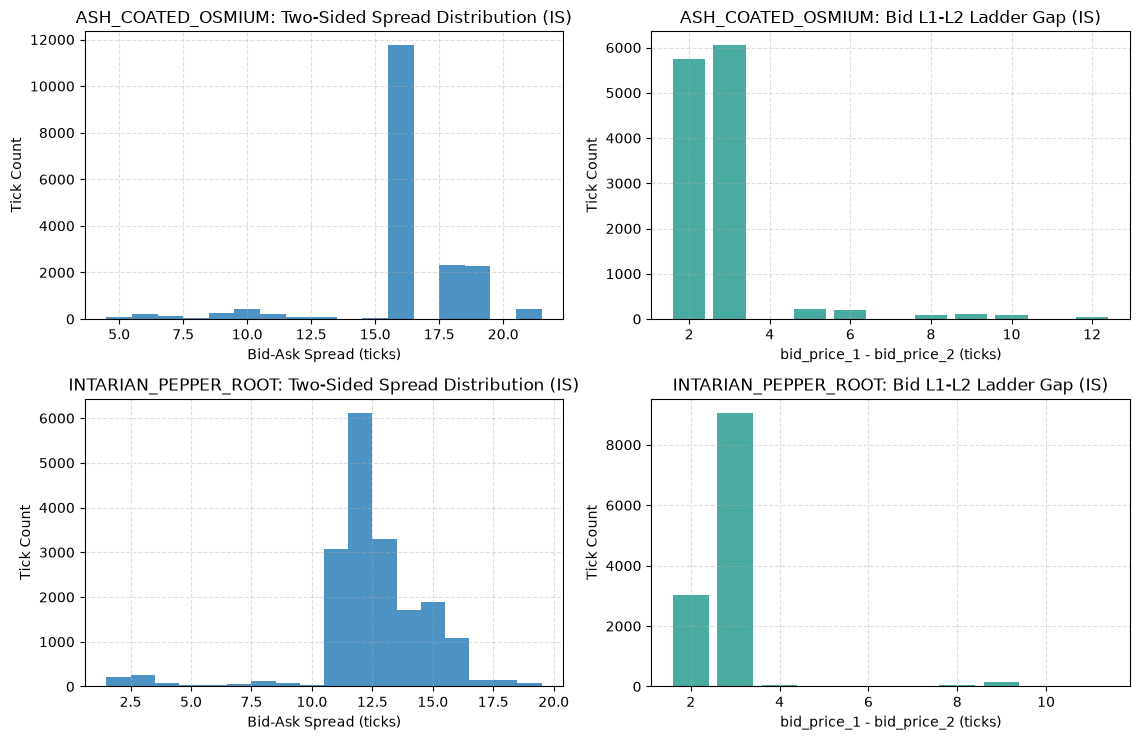

In [2]:
is_r1 = pd.concat([loader.load_day_prices(1, -2), loader.load_day_prices(1, -1)], ignore_index=True)
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.5))

for row_idx, sym in enumerate(["ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"]):
    sub = is_r1[is_r1["product"] == sym]
    both = sub["bid_price_1"].notna() & sub["ask_price_1"].notna()
    valid = sub.loc[both]
    spread = valid["ask_price_1"] - valid["bid_price_1"]
    gap12 = (valid["bid_price_1"] - valid["bid_price_2"]).dropna()

    axes[row_idx, 0].hist(spread, bins=range(int(spread.min()), int(spread.max()) + 2), align="left", alpha=0.8)
    axes[row_idx, 0].set_title(f"{sym}: Two-Sided Spread Distribution (IS)")
    axes[row_idx, 0].set_xlabel("Bid-Ask Spread (ticks)")
    axes[row_idx, 0].set_ylabel("Tick Count")
    axes[row_idx, 0].grid(True, linestyle="--", alpha=0.4)

    vc = gap12.value_counts().sort_index().head(10)
    axes[row_idx, 1].bar(vc.index.astype(int), vc.values, color="#2a9d8f", alpha=0.85)
    axes[row_idx, 1].set_title(f"{sym}: Bid L1-L2 Ladder Gap (IS)")
    axes[row_idx, 1].set_xlabel("bid_price_1 - bid_price_2 (ticks)")
    axes[row_idx, 1].set_ylabel("Tick Count")
    axes[row_idx, 1].grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()